---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 11

- 13524027 Aufa Rienaldifaza Ahmad
- 13524045 Ahmad Zaky Robbani
- 13524075 Hakam Avicena Mustain
- 13524087 Muhammad Fakhry Zaki
- 13524099 Muhammad Akmal

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [59]:
# %pip install -q numpy pandas

Note: you may need to restart the kernel to use updated packages.


d:\Akademik\Semester_5\IntelijensiArtifisial\tubes\IF3170_besokaja\.venv\Scripts\python.exe: No module named pip


## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import calendar
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path.cwd() / 'src'))

pd.set_option('display.max_columns', None)

## Settings

Paths and shared constants are kept in this class.

In [61]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')
    ID_COLUMN = 'id'
    TARGET = 'is_canceled'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [62]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [64]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [65]:
num_cols = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "arrival_year", "arrival_month", "arrival_day",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests"
]
cat_cols = ["meal_package", "room_category", "booking_channel"]
bin_cols = ["needs_parking", "is_returning_guest"]
target_col = "is_canceled"

print('\nTRAIN INFO')
train_df.info()
print('\nTEST INFO')
test_df.info()

train_df.head()


TRAIN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  int64  

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


## Explore Data

This part covers distributions and relationships between attributes.

is_canceled
0    18404
1     8969
Name: count, dtype: int64

Target distribution (%)
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64


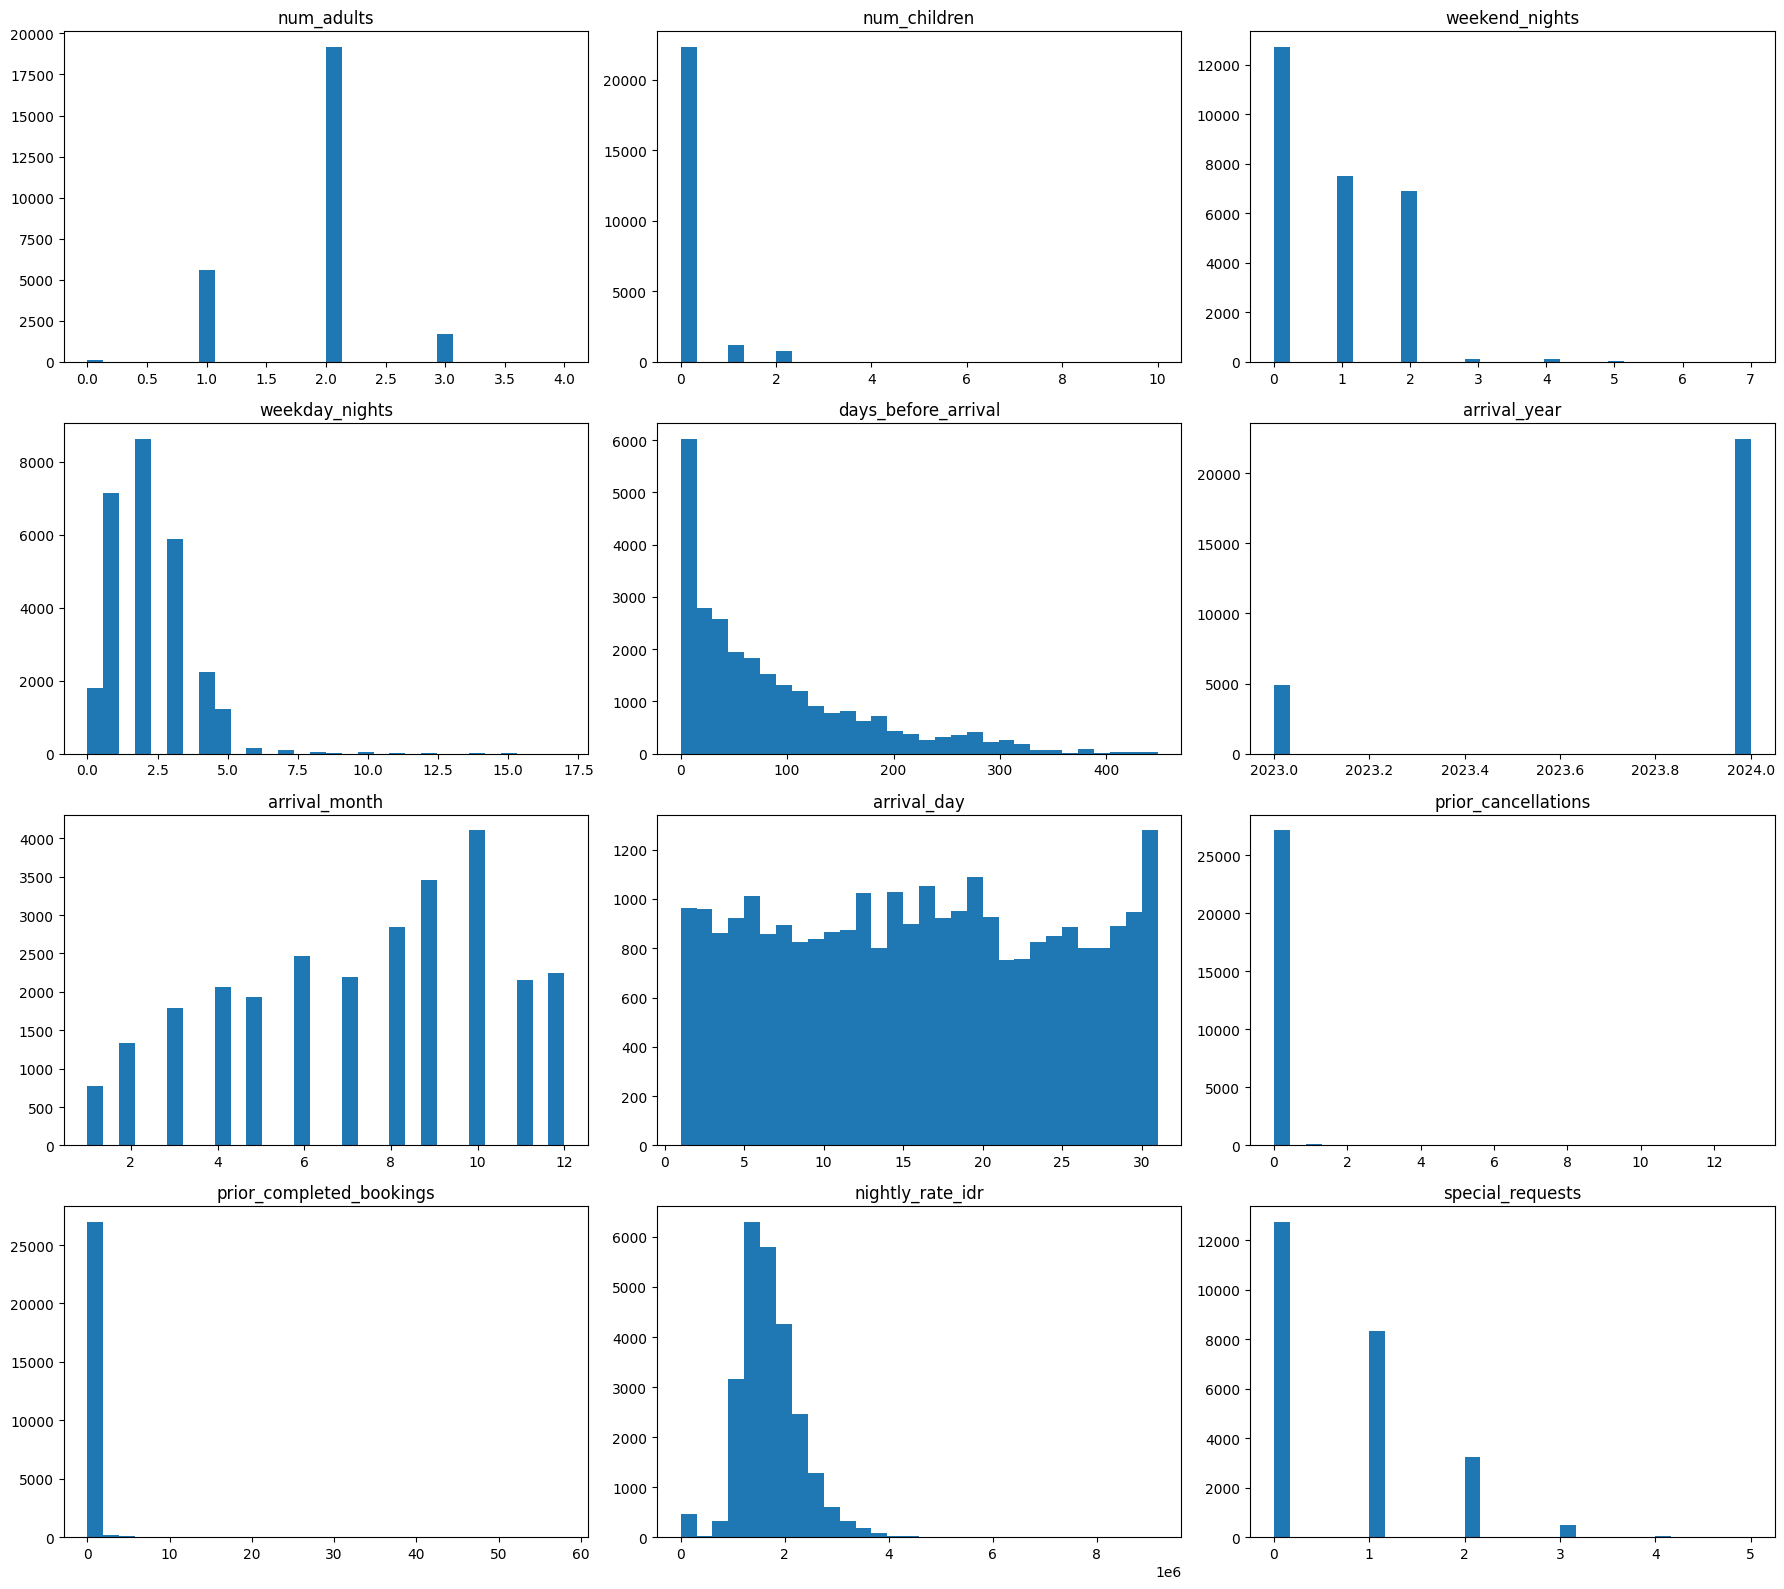

--- meal_package ---
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64
--- room_category ---
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
--- booking_channel ---
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
--- needs_parking ---
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64
--- is_returning_guest ---
is_returning_guest
0    26684
1      689
Name: count, dtype: int64


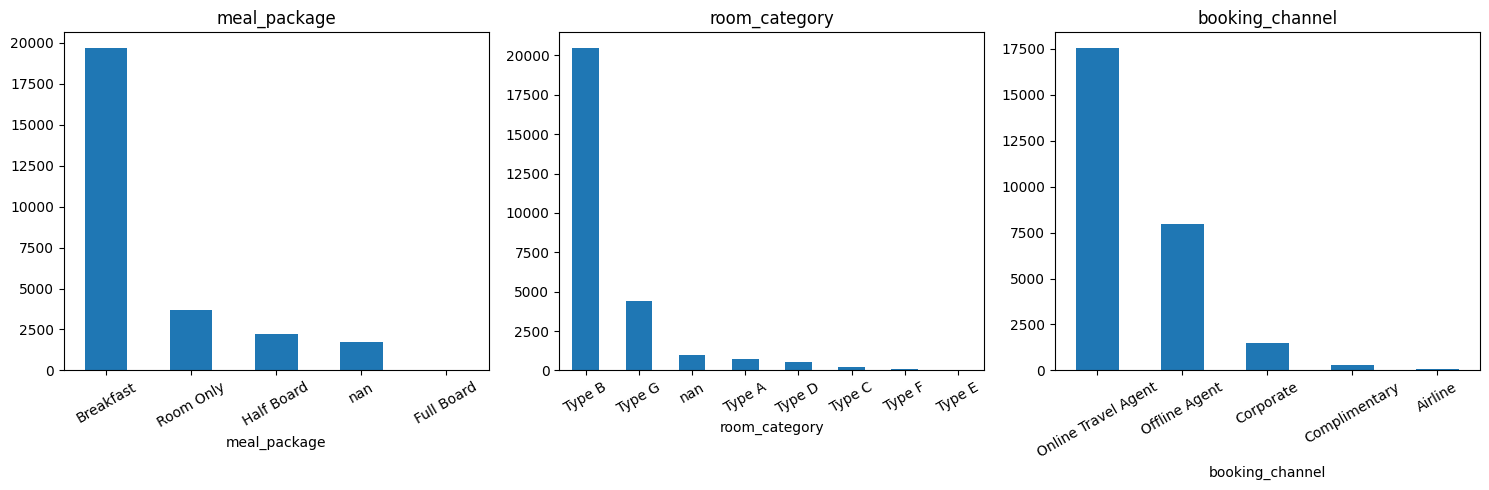


Numeric correlations with target:
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
special_requests           -0.257996
Name: is_canceled, dtype: float64


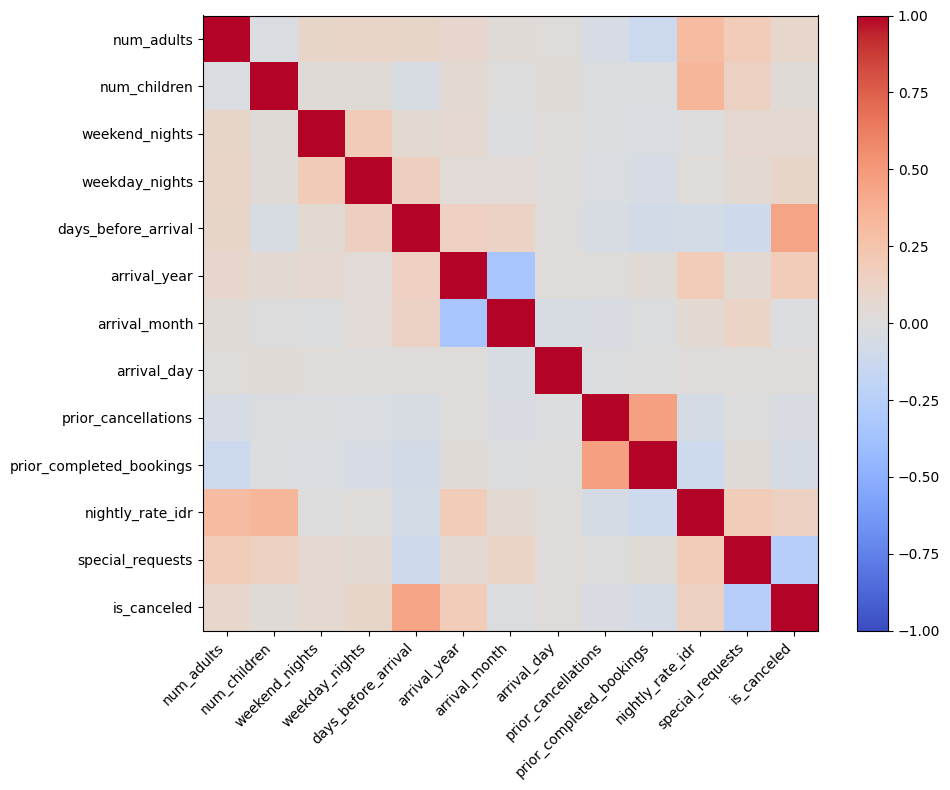


Cancellation rate by meal_package:
meal_package
Half Board    0.459
Room Only     0.338
NaN           0.319
Breakfast     0.311
Full Board    0.250
Name: is_canceled, dtype: float64

Cancellation rate by room_category:
room_category
Type A    0.426
NaN       0.348
Type G    0.342
Type D    0.329
Type B    0.321
Type E    0.286
Type C    0.249
Type F    0.244
Name: is_canceled, dtype: float64

Cancellation rate by booking_channel:
booking_channel
Online Travel Agent    0.364
Airline                0.307
Offline Agent          0.302
Corporate              0.115
Complimentary          0.000
Name: is_canceled, dtype: float64


In [66]:
print(train_df[target_col].value_counts())
print('\nTarget distribution (%)')
print((train_df[target_col].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for axis, column in zip(axes.flat, num_cols):
    axis.hist(train_df[column].dropna(), bins=30)
    axis.set_title(column)
plt.tight_layout()
plt.show()

for column in cat_cols + bin_cols:
    print(f'--- {column} ---')
    print(train_df[column].value_counts(dropna=False))

fig, axes = plt.subplots(1, len(cat_cols), figsize=(15, 5))
for axis, column in zip(axes, cat_cols):
    train_df[column].value_counts(dropna=False).plot(kind='bar', ax=axis)
    axis.set_title(column)
    axis.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

correlation = train_df[num_cols + [target_col]].corr()
print('\nNumeric correlations with target:')
print(correlation[target_col].drop(target_col).sort_values(ascending=False))
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
axis.set_yticks(range(len(correlation.index)), correlation.index)
fig.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

for column in cat_cols:
    rate = train_df.groupby(column, dropna=False)[target_col].mean().sort_values(ascending=False)
    print(f'\nCancellation rate by {column}:')
    print(rate.round(3))

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [67]:
def missing_report(df, name):
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": miss, "missing_pct": pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print(f"--- Missing values: {name} ---")
    print(report if not report.empty else "Tidak ada missing value.")
    return report

In [68]:
def iqr_outlier_count(series: pd.Series) -> int:
    values = series.dropna()
    if values.empty:
        return 0

    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower_bound) | (values > upper_bound)).sum())

In [69]:
def invalid_date_mask(df: pd.DataFrame) -> pd.Series:
    required_columns = {"arrival_year", "arrival_month", "arrival_day"}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    def is_invalid_date(row: pd.Series) -> bool:
        try:
            max_day = calendar.monthrange(
                int(row["arrival_year"]), int(row["arrival_month"])
            )[1]
            return row["arrival_day"] > max_day
        except (OverflowError, TypeError, ValueError):
            return False

    return df.apply(is_invalid_date, axis=1)

In [70]:
missing_report(train_df, 'train')
missing_report(test_df, 'test')

print('\nDuplicate rows (train):', train_df.duplicated().sum())
print('Duplicate rows (test):', test_df.duplicated().sum())
print('Duplicate ids (train):', train_df['id'].duplicated().sum())
print('Duplicate ids (test):', test_df['id'].duplicated().sum())

for column in num_cols:
    print(f'{column}: {iqr_outlier_count(train_df[column])} potential outliers (IQR rule)')

zero_nights = train_df[
    (train_df['weekend_nights'] == 0) & (train_df['weekday_nights'] == 0)
]
zero_guests = train_df[
    (train_df['num_adults'] == 0) & (train_df['num_children'] == 0)
]
print('\nBookings with zero nights:', len(zero_nights))
print('Bookings with zero guests:', len(zero_guests))

invalid_dates = train_df.loc[invalid_date_mask(train_df)]
print('Invalid arrival dates:', len(invalid_dates))

--- Missing values: train ---
                     missing_count  missing_pct
num_children                  3035        11.09
special_requests              2500         9.13
nightly_rate_idr              2038         7.45
meal_package                  1760         6.43
days_before_arrival           1123         4.10
needs_parking                 1082         3.95
room_category                 1002         3.66
num_adults                     809         2.96
--- Missing values: test ---
                     missing_count  missing_pct
num_children                   747        10.91
special_requests               593         8.66
nightly_rate_idr               540         7.89
meal_package                   442         6.46
days_before_arrival            290         4.24
needs_parking                  247         3.61
room_category                  242         3.54
num_adults                     180         2.63

Duplicate rows (train): 0
Duplicate rows (test): 0
Duplicate ids (train): 0


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [ ]:
X_test = train_df.drop(columns=[Settings.ID_COLUMN])
X = train_df.drop(columns=[Settings.ID_COLUMN, Settings.TARGET])
y = train_df[Settings.TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, train_size=0.75, stratify=y, random_state=CFG.SEED
)
pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [72]:
# Write your code here

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [73]:
def clean_data(
    df: pd.DataFrame,
    is_train: bool = True,
    imputers: dict[str, object] | None = None,
) -> pd.DataFrame | tuple[pd.DataFrame, dict[str, object]]:
    """Impute missing values and clean training duplicates using train statistics."""
    df = df.copy()
    fitted_imputers = {} if imputers is None else imputers

    if is_train:
        before = len(df)
        df = df.drop_duplicates()
        print(f"[train] Removed {before - len(df)} duplicate rows")

    for column in num_cols:
        if column not in df.columns:
            continue
        if imputers is None:
            if not df[column].notna().any():
                raise ValueError(
                    f"Cannot impute {column}: column contains no numeric values"
                )
            median = df[column].median()
            fitted_imputers[column] = median
        df[column] = df[column].fillna(fitted_imputers[column])

    for column in cat_cols + num_cols:
        if column not in df.columns:
            continue
        if imputers is None:
            modes = df[column].mode()
            if modes.empty:
                raise ValueError(f"Cannot impute {column}: column contains no values")
            fitted_imputers[column] = modes.iloc[0]
        df[column] = df[column].fillna(fitted_imputers[column])

    present_int_columns = [
        "num_adults", "num_children", "weekend_nights", "weekday_nights",
        "needs_parking", "arrival_year", "arrival_month", "arrival_day",
        "is_returning_guest", "prior_cancellations", "prior_completed_bookings",
        "nightly_rate_idr", "special_requests"
    ]
    remaining_na = df[present_int_columns].isna().sum()
    if remaining_na.sum() > 0:
        print("Missing integer-like values remain; filling with training medians:")
        print(remaining_na[remaining_na > 0])
        for column in present_int_columns:
            if df[column].isna().any():
                fallback = fitted_imputers.get(column, df[column].median())
                df[column] = df[column].fillna(fallback)

    for column in present_int_columns:
        df[column] = df[column].round().astype(int)

    if imputers is None:
        return df, fitted_imputers
    return df

In [ ]:
X_train, imputers = clean_data(X_train, is_train=True)
X_val = clean_data(X_val, is_train=False, imputers=imputers)
X_test = clean_data(X_test, is_train=False, imputers=imputers)

print('\nMissing values after cleaning (train):', X_train.isna().sum().sum())
print('\nMissing values after cleaning (validation):', X_val.isna().sum().sum())
print('Missing values after cleaning (test):', X_test.isna().sum().sum())

X_train.to_csv(CFG.OUTPUT_DIR / 'train_clean.csv', index=False)
X_val.to_csv(CFG.OUTPUT_DIR / 'validation_clean.csv', index=False)
X_test.to_csv(CFG.OUTPUT_DIR / 'test_clean.csv', index=False)
print(f'Cleaned datasets saved to {CFG.OUTPUT_DIR.resolve()}')

[train] Removed 0 duplicate rows
Missing integer-like values remain; filling with training medians:
needs_parking    1082
dtype: int64
Missing integer-like values remain; filling with training medians:
needs_parking    247
dtype: int64

Missing values after cleaning (train): 0
Missing values after cleaning (test): 0
Cleaned datasets saved to D:\Akademik\Semester_5\IntelijensiArtifisial\tubes\IF3170_besokaja\output


### Duplicates

This part covers repeated records.

In [ ]:
print('Duplicate rows after cleaning (train):', X_train.duplicated().sum())
print('Duplicate rows after cleaning (validation):', X_val.duplicated().sum())
print('Duplicate rows after cleaning (test):', X_test.duplicated().sum())

Duplicate rows after cleaning (train): 0
Duplicate rows after cleaning (test): 0


### Outliers

This part covers values far from the rest of the data.

In [ ]:
print('--- Outlier SEBELUM capping ---')
before_counts = {col: iqr_outlier_count(train_clean[col]) for col in num_cols}
for column, count in before_counts.items():
    print(f'{column}: {count} potential outliers')

def batasan_outlier(df: pd.DataFrame, columns: list[str], k: float = 3.0) -> dict:
    batas = {}
    for column in columns:
        values = df[column].dropna()
        q1, q3 = values.quantile(0.25), values.quantile(0.75)
        iqr = q3 - q1
        lower = max(q1 - k * iqr, 0)
        upper = q3 + k * iqr
        batas[column] = (lower, upper)
    return batas


def cap_outliers(df: pd.DataFrame, bounds: dict) -> pd.DataFrame:
    df = df.copy()
    for column, (lower, upper) in bounds.items():
        if column not in df.columns:
            continue
        n_capped = ((df[column] < lower) | (df[column] > upper)).sum()
        if n_capped > 0:
            print(f'{column}: {n_capped} nilai di-cap ke [{lower:.1f}, {upper:.1f}]')
        df[column] = df[column].clip(lower=lower, upper=upper)
    return df


outlier_cols = ['nightly_rate_idr', 'days_before_arrival', 'special_requests']

outlier_bounds = batasan_outlier(X_train, outlier_cols, k=3.0)
print('\\nBounds (fitted dari train):', outlier_bounds)

print('\\n--- Capping train ---')
train_clean = cap_outliers(X_train, outlier_bounds)

print('\\n--- Capping val ---')
test_clean = cap_outliers(X_val, outlier_bounds)

print('\\n--- Capping test ---')
test_clean = cap_outliers(X_test, outlier_bounds)

print('\\n--- Outlier SESUDAH capping ---')
for column in outlier_cols:
    print(f'{column}: before={before_counts[column]}, after={iqr_outlier_count(train_clean[column])}')

num_adults: 7400 potential outliers remain
num_children: 2020 potential outliers remain
weekend_nights: 16 potential outliers remain
weekday_nights: 258 potential outliers remain
days_before_arrival: 1107 potential outliers remain
arrival_year: 4924 potential outliers remain
arrival_month: 0 potential outliers remain
arrival_day: 0 potential outliers remain
prior_cancellations: 241 potential outliers remain
prior_completed_bookings: 600 potential outliers remain
nightly_rate_idr: 1367 potential outliers remain
special_requests: 563 potential outliers remain


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [ ]:
invalid_date_train = X_train.loc[invalid_date_mask(X_train)]
print('Invalid arrival dates after cleaning (train):', len(invalid_date_train))
print('\nInteger-like column types after cleaning:')
print(X_train[[column for column in num_cols if column in X_train.columns]].dtypes)

invalid_date_val = X_val.loc[invalid_date_mask(X_val)]
print('Invalid arrival dates after cleaning (val):', len(invalid_date_val))
print('\nInteger-like column types after cleaning:')
print(X_val[[column for column in num_cols if column in X_val.columns]].dtypes)

invalid_date_test = X_test.loc[invalid_date_mask(X_test)]
print('Invalid arrival dates after cleaning (test):', len(invalid_date_test))
print('\nInteger-like column types after cleaning:')
print(X_test[[column for column in num_cols if column in X_test.columns]].dtypes)

print('--- Cek nilai negatif (seharusnya mustahil untuk SEMUA kolom numerik) ---')
has_negative = False
for column in num_cols:
    n_negative = (X_train[column] < 0).sum()
    n_negative_val = (X_val[column] < 0).sum()
    n_negative_test = (X_test[column] < 0).sum()
    if n_negative > 0 or n_negative_test > 0 or n_negative_val > 0:
        has_negative = True
        print(f'{column}: {n_negative} negatif di train, {n_negative_val} negatif di validation, {n_negative_test} di test — PERLU DITANGANI')
    else:
        print(f'{column}: aman')

Invalid arrival dates after cleaning: 0

Integer-like column types after cleaning:
num_adults                    int64
num_children                  int64
weekend_nights                int64
weekday_nights                int64
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr              int64
special_requests              int64
dtype: object


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [ ]:
class AttributeConstructor(BaseEstimator, TransformerMixin):
    def __init__(self, eps=0.001):
        self.eps = eps

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        transformed:pd.DataFrame = X.copy()
        transformed["has_children"] = (transformed["num_children"] > 0).astype(int)
        transformed["total_guests"] = (
            transformed["num_adults"] + transformed["num_children"]
        )
        transformed["total_nights"] = (
            transformed["weekday_nights"] + transformed["weekend_nights"]
        )
        transformed["weekend_ratio"] = transformed["weekend_nights"].div(transformed["total_nights"] + self.eps)
        
        transformed["log_total_nights"] = np.log1p(transformed["total_nights"])
    
        transformed["log_days_before_arrival"] = np.log1p(
            transformed["days_before_arrival"]
        )
        transformed["is_2024"] = (transformed["arrival_year"] == 2024).astype(int)
        transformed["month_sin"] = np.sin(
            2 * np.pi * transformed["arrival_month"] / 12
        )
        transformed["month_cos"] = np.cos(
            2 * np.pi * transformed["arrival_month"] / 12
        )
        transformed["day_sin"] = np.sin(2 * np.pi * transformed["arrival_day"] / 30)
        transformed["day_cos"] = np.cos(2 * np.pi * transformed["arrival_day"] / 30)
    
        transformed["total_bookings"] = (
            transformed["prior_cancellations"]
            + transformed["prior_completed_bookings"]
        )
        transformed["cancellation_ratio"] = transformed["prior_cancellations"].div(
            transformed["total_bookings"] + self.eps
        )
        transformed["is_new_customer"] = (transformed["total_bookings"] == 0).astype(int)
        transformed["log_total_prior_bookings"] = np.log1p(
            transformed["total_bookings"]
        )
        return transformed

    def set_output(self, *, transform=None):
        return self

guests with children in general typically differ in behavior so `num_children` is generalized into `has_children`. `total_guests` generalizes the guest count regardless of age (adult or children).

Continue later.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [ ]:
to_scale = [
    "total_guests",
    "log_total_nights",
    "log_days_before_arrival",
    "total_bookings"
]

scale_transformer = ColumnTransformer(
    [("scale", StandardScaler(), to_scale)],
    remainder='passthrough'
)

decision

### Encoding

This part covers the numeric representation of categorical attributes.

In [ ]:
# Write your code here
class FeatureEncoder(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        one_hot_cols=("room_category", "booking_channel"),
        meal_order=("Room Only", "Breakfast", "Half Board", "Full Board"),
        meal_cap=2,
    ):
        self.one_hot_cols = one_hot_cols
        self.meal_order = meal_order
        self.meal_cap = meal_cap

    def fit(self, X: pd.DataFrame, y=None):
        cols = list(self.one_hot_cols)
        self.ohe_ = OneHotEncoder(
            drop="first", sparse_output=False, handle_unknown="ignore"
        ).fit(X[cols])
        self.meal_map_ = {
            meal: min(i, self.meal_cap) for i, meal in enumerate(self.meal_order)
        }
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        cols = list(self.one_hot_cols)
        result = X.copy()

        encoded = pd.DataFrame(
            self.ohe_.transform(result[cols]),
            columns=self.ohe_.get_feature_names_out(cols),
            index=result.index,
        )
        result = pd.concat([result.drop(columns=cols), encoded], axis=1)

        meal_values = result["meal_package"].map(self.meal_map_)
        if meal_values.isna().any():
            invalid = result.loc[meal_values.isna(), "meal_package"].unique()
            raise ValueError(f"Unknown meal_package values: {invalid.tolist()}")
        result["meal_package"] = meal_values

        return result
    

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [ ]:
# Write your code here


## Class Balance

This part covers the proportion of each class in the training data.

In [82]:
# Write your code here

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [83]:
# Write your code here

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [ ]:
# Write your code here
preparation = Pipeline([
    ("construct", AttributeConstructor()),
    ("scale", scale_transformer),
    ("encode", FeatureEncoder())
])

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [85]:
# Write your code here

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [86]:
# Write your code here

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [87]:
# Write your code here

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [88]:
# Write your code here

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [89]:
# Write your code here

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [90]:
# Write your code here

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [91]:
# Write your code here

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [92]:
# Write your code here

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [93]:
# Write your code here

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [94]:
# Write your code here

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.